# 17 · Integrated energy systems: an energy hub coupling electricity, heat and gas
**Level 6 · System integration** &nbsp;|&nbsp; Course link: *the "integrated" in Intelligent and Integrated Energy
Systems: sector coupling, multi-energy flexibility, decision support across carriers*

Electricity, heat and gas are planned separately today, but the technologies that decarbonise them **couple** them:
a heat pump turns electricity into heat, a combined heat-and-power plant (CHP) turns gas into both, a hot-water tank
stores heat cheaply. The **energy hub** model (Geidl & Andersson, 2007) treats a district as one node with carriers in,
converters inside, and demands out:

```
 grid electricity ─┐            ┌─► heat pump ──────┐
 rooftop PV ───────┼─► [ el ] ──┤                   ├─► [ heat ] ─► district heat demand
 natural gas ──────┼─► CHP ─────┴─► (el + heat) ────┤        ▲
                   └─► gas boiler ──────────────────┘        └─ thermal storage
                                    [ el ] ─► electricity demand
```

**District:** ~1 000 homes near Berlin, real 2019 weather, German day-ahead prices; the grid's carbon intensity is
estimated hour by hour from the share of wind and solar in German demand.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pyomo.environ as pyo
from energy_ai import weather, opsd, day_ahead_price, style
style()

w = weather(52.52, 13.40, "2019-01-01", "2019-12-31")
w.index = w.index.tz_localize(None) if w.index.tz is not None else w.index
de = opsd("DE", "2019-01-01", "2019-12-31")
de.index = de.index.tz_localize(None) if de.index.tz is not None else de.index
price = day_ahead_price("DE_LU", "2019-01-01", "2019-12-31")
price.index = price.index.tz_localize(None)
df = pd.DataFrame({"T": w.temperature_2m, "ghi": w.shortwave_radiation}).join(price.rename("price")).join(de).interpolate(limit=3).dropna()

res_share = ((df.solar_mw + df.wind_onshore_mw + df.wind_offshore_mw) / df.load_mw).clip(0, 1)
df["ci_grid"] = 0.75 * (1 - res_share) + 0.02                                 # t CO2 / MWh, crude marginal proxy
hdh = np.maximum(15.5 - df["T"], 0)                                           # heating degree-hours
dhw = 0.6 + 0.4 * np.isin(df.index.hour, [6, 7, 8, 18, 19, 20, 21])         # domestic hot water [MW]
df["heat"] = 0.32 * hdh + dhw                                                 # MW_th for ~1 000 homes
df["elec"] = 0.55 + 0.45 * (df.load_mw / df.load_mw.max())                    # MW_el, follows the national shape
df["pv"] = 1.5 * df.ghi / 1000 * 0.8                                          # 1.5 MWp of rooftop PV
df["cop"] = np.clip(3.3 + 0.08 * (df["T"] - 7), 1.8, 5.0)                     # air-source heat pump
print(f"annual heat {df.heat.sum() / 1e3:.1f} GWh (peak {df.heat.max():.1f} MW) | electricity {df.elec.sum() / 1e3:.1f} GWh | "
      f"grid CO2 proxy {df.ci_grid.min():.2f}–{df.ci_grid.max():.2f} t/MWh")

annual heat 22.8 GWh (peak 8.3 MW) | electricity 7.7 GWh | grid CO2 proxy 0.07–0.76 t/MWh


## 1. The hub as a linear programme
For every hour $t$: electricity balance, heat balance, converter equations, storage dynamics.
$$\underbrace{g^{in}_t - g^{out}_t + PV_t + \eta^{el}_{CHP} f^{CHP}_t - e^{HP}_t}_{\text{electricity}} = D^{el}_t,\qquad
\underbrace{\eta^{th}_{CHP} f^{CHP}_t + \eta_B f^{B}_t + COP_t\, e^{HP}_t + d_t - c_t}_{\text{heat}} \ge D^{th}_t$$
$$s_t = (1-\ell)\,s_{t-1} + c_t - d_t,\qquad \min \sum_t \pi_t g^{in}_t - 0.9\,\pi_t g^{out}_t + \pi^{gas}(f^{CHP}_t + f^B_t) + \pi^{CO_2}\,\text{CO}_{2,t}$$

In [2]:
GAS, CO2_GAS = 25.0, 0.20                                                     # €/MWh gas, t CO2/MWh gas
CONFIGS = {
    "1. gas boilers": dict(boiler=12, hp=0, chp=0, tes=0),
    "2. heat pumps": dict(boiler=12, hp=6.0, chp=0, tes=0),
    "3. heat pumps + heat storage": dict(boiler=12, hp=6.0, chp=0, tes=40),
    "4. hybrid: HP + CHP + storage": dict(boiler=12, hp=6.0, chp=1.5, tes=40),
}

def solve_hub(d, cfg, carbon_price=80.0):
    T = range(len(d)); m = pyo.ConcreteModel()
    m.gi = pyo.Var(T, bounds=(0, None)); m.go = pyo.Var(T, bounds=(0, None))
    m.fb = pyo.Var(T, bounds=(0, cfg["boiler"] / 0.92))
    m.ehp = pyo.Var(T, bounds=lambda m, t: (0, cfg["hp"] / d.cop.iloc[t]))      # hp = thermal capacity [MW_th]
    m.fchp = pyo.Var(T, bounds=(0, cfg["chp"] / 0.38))
    m.c = pyo.Var(T, bounds=(0, cfg["tes"] / 4)); m.dis = pyo.Var(T, bounds=(0, cfg["tes"] / 4)); m.s = pyo.Var(T, bounds=(0, cfg["tes"]))
    m.el = pyo.Constraint(T, rule=lambda m, t: m.gi[t] - m.go[t] + d.pv.iloc[t] + 0.38 * m.fchp[t] - m.ehp[t] == d.elec.iloc[t])
    m.ht = pyo.Constraint(T, rule=lambda m, t: 0.47 * m.fchp[t] + 0.92 * m.fb[t] + d.cop.iloc[t] * m.ehp[t] + m.dis[t] - m.c[t] >= d.heat.iloc[t])
    m.st = pyo.Constraint(T, rule=lambda m, t: m.s[t] == (m.s[t - 1] if t else 0.5 * cfg["tes"]) * 0.995 + m.c[t] - m.dis[t])
    m.end = pyo.Constraint(expr=m.s[len(d) - 1] >= 0.5 * cfg["tes"])
    m.co2 = pyo.Expression(expr=sum(d.ci_grid.iloc[t] * m.gi[t] + CO2_GAS * (m.fb[t] + m.fchp[t]) for t in T))
    m.cost = pyo.Expression(expr=sum(d.price.iloc[t] * m.gi[t] - 0.9 * d.price.iloc[t] * m.go[t] + GAS * (m.fb[t] + m.fchp[t]) for t in T))
    m.obj = pyo.Objective(expr=m.cost + carbon_price * m.co2)
    pyo.SolverFactory("appsi_highs").solve(m)
    out = pd.DataFrame({"boiler": [0.92 * pyo.value(m.fb[t]) for t in T], "heat pump": [d.cop.iloc[t] * pyo.value(m.ehp[t]) for t in T],
                        "CHP heat": [0.47 * pyo.value(m.fchp[t]) for t in T], "storage out": [pyo.value(m.dis[t] - m.c[t]) for t in T],
                        "soc": [pyo.value(m.s[t]) for t in T], "hp_el": [pyo.value(m.ehp[t]) for t in T],
                        "chp_el": [0.38 * pyo.value(m.fchp[t]) for t in T], "import": [pyo.value(m.gi[t]) for t in T]}, index=d.index)
    return pyo.value(m.cost), pyo.value(m.co2), out

weeks = {"winter week (Jan)": df.loc["2019-01-21":"2019-01-27"], "spring week (Apr)": df.loc["2019-04-08":"2019-04-14"]}
rows, runs = [], {}
for wk, d in weeks.items():
    for name, cfg in CONFIGS.items():
        cost, co2, out = solve_hub(d, cfg); runs[(wk, name)] = out
        rows.append({"week": wk, "configuration": name, "energy cost [k€]": cost / 1e3, "CO2 [t]": co2,
                     "cost incl. CO2 at 80 €/t [k€]": (cost + 80 * co2) / 1e3})
tab = pd.DataFrame(rows).set_index(["week", "configuration"])
display(tab.round(1))

energy cost [k€]  CO2 [t]  \
week              configuration                                              
winter week (Jan) 1. gas boilers                             38.8    325.7   
                  2. heat pumps                              35.2    314.4   
                  3. heat pumps + heat storage               34.9    312.1   
                  4. hybrid: HP + CHP + storage              28.1    237.2   
spring week (Apr) 1. gas boilers                             23.2    212.7   
                  2. heat pumps                              14.4    189.6   
                  3. heat pumps + heat storage               13.7    180.4   
                  4. hybrid: HP + CHP + storage              14.8    130.3   

                                                 cost incl. CO2 at 80 €/t [k€]  
week              configuration                                                 
winter week (Jan) 1. gas boilers                                          64.9  
                  2. heat pumps                                           60.4  
                  3. heat pumps + heat storage                            59.9  
                  4. hybrid: HP + CHP + storage                           47.1  
spring week (Apr) 1. gas boilers                                          40.2  
                  2. heat pumps                                           29.5  
                  3. heat pumps + heat storage                            28.1  
                  4. hybrid: HP + CHP + storage                           25.3

**Reading the table** (each configuration is optimised for cost + 80 €/t × CO2, the last column):
* Heat pumps beat gas boilers in both weeks, by far more in spring when the COP is higher.
* The heat store adds little in the cold week (the heat pump runs near full output anyway) but more in spring, when
  there is spare heat-pump capacity to move into cheap, low-carbon hours.
* The CHP cuts CO2 strongly because its electricity replaces grid power that, in our proxy, is coal-heavy in 2019.

## 2. How the hybrid hub operates (winter week, carbon price 80 €/t)

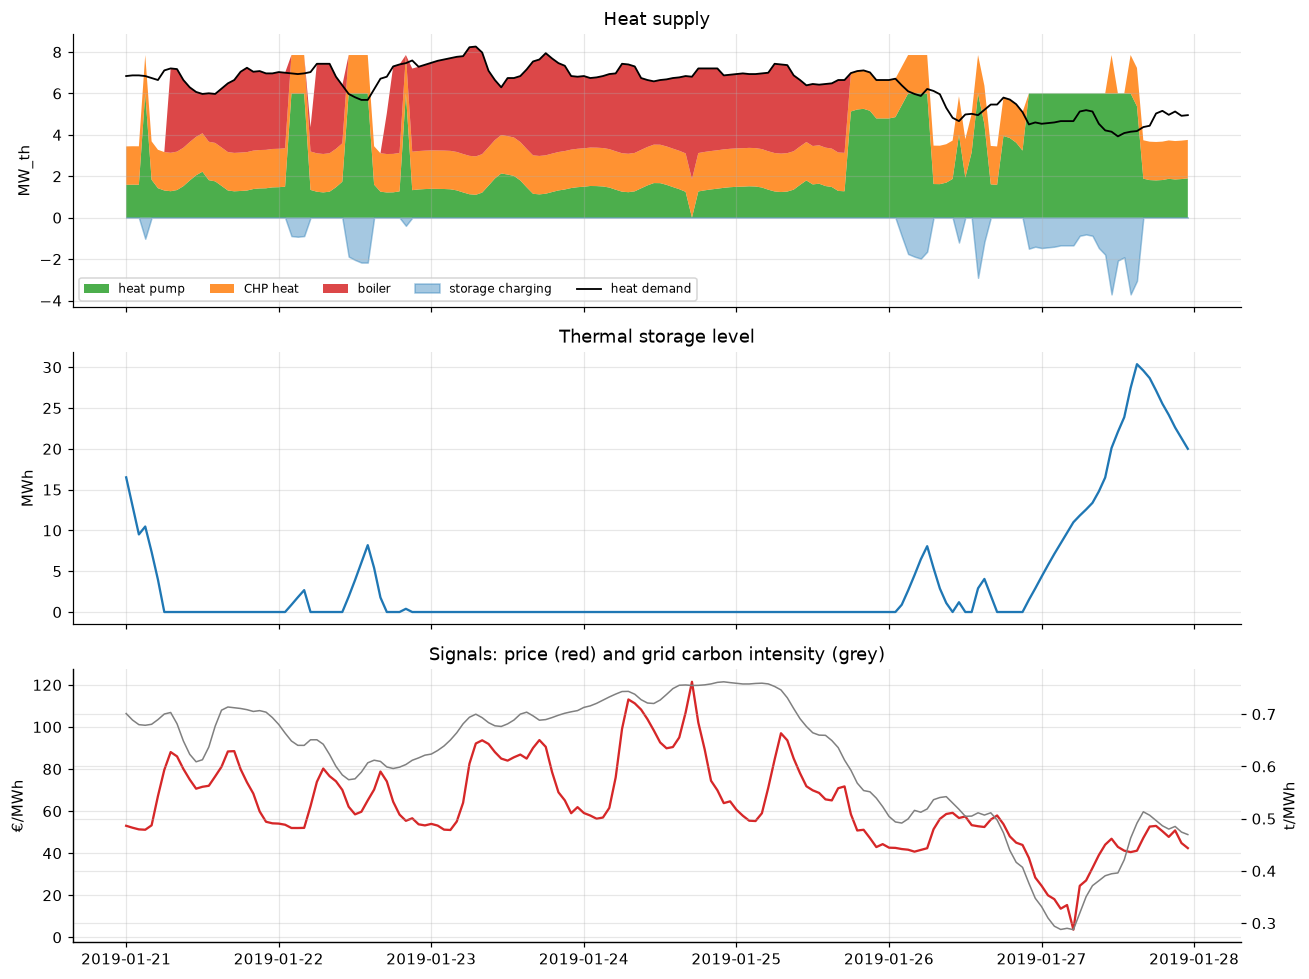

correlation with the electricity price: heat-pump consumption -0.63 | CHP generation +0.54


In [3]:
d, out = weeks["winter week (Jan)"], runs[("winter week (Jan)", "4. hybrid: HP + CHP + storage")]
fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
supply = out[["heat pump", "CHP heat", "boiler"]].clip(lower=0)
ax[0].stackplot(out.index, supply.T.values, labels=supply.columns, colors=["tab:green", "tab:orange", "tab:red"], alpha=0.85)
ax[0].fill_between(out.index, 0, out["storage out"].clip(upper=0), color="tab:blue", alpha=0.4, label="storage charging")
ax[0].plot(d.index, d.heat, "k", lw=1.2, label="heat demand"); ax[0].set(ylabel="MW_th", title="Heat supply"); ax[0].legend(ncol=5, fontsize=8)
ax[1].plot(out.index, out.soc, color="tab:blue"); ax[1].set(ylabel="MWh", title="Thermal storage level")
ax[2].plot(d.index, d.price, color="tab:red", label="day-ahead price [€/MWh]")
ax2 = ax[2].twinx(); ax2.plot(d.index, d.ci_grid, color="0.5", lw=1, label="grid CO2 [t/MWh]"); ax2.set_ylabel("t/MWh")
ax[2].set(ylabel="€/MWh", title="Signals: price (red) and grid carbon intensity (grey)")
plt.tight_layout(); plt.show()

corr = np.corrcoef(out.hp_el, d.price)[0, 1], np.corrcoef(out.chp_el, d.price)[0, 1]
print(f"correlation with the electricity price: heat-pump consumption {corr[0]:+.2f} | CHP generation {corr[1]:+.2f}")

## 3. Sector coupling responds to the carbon price
Sweep the carbon price for the hybrid hub in the winter week: which converter supplies the heat?

In [4]:
sweep = []
for cp in (0, 25, 50, 80, 120, 200):
    cost, co2, out = solve_hub(weeks["winter week (Jan)"], CONFIGS["4. hybrid: HP + CHP + storage"], carbon_price=cp)
    tot = out[["heat pump", "CHP heat", "boiler"]].clip(lower=0).sum()
    sweep.append({"carbon price [€/t]": cp, "CO2 [t]": co2, **(tot / tot.sum()).add_prefix("share ").to_dict()})
sweep = pd.DataFrame(sweep).set_index("carbon price [€/t]")
display(sweep.style.format({"CO2 [t]": "{:.0f}", "share heat pump": "{:.0%}", "share CHP heat": "{:.0%}", "share boiler": "{:.0%}"}))

,CO2 [t],share heat pump,share CHP heat,share boiler
carbon price [€/t],,,,
0,268,52%,24%,24%
25,253,49%,26%,25%
50,243,47%,26%,27%
80,237,41%,26%,33%
120,236,39%,27%,35%
200,235,38%,27%,35%


**A surprise worth understanding:** in this cold, windless week a *higher* carbon price makes the hub use the heat pump
**less**. Per MWh of heat, the heat pump emits (grid intensity ÷ COP) ≈ 0.61 ÷ 2.55 ≈ 0.25 t, the gas boiler
0.20 ÷ 0.92 ≈ 0.22 t: with coal-heavy marginal power and a low COP, gas is cleaner in most hours (the heat pump is
cleaner in only ~30 % of the hours this week, but ~86 % in the spring week). Whether electrifying heat cuts emissions
depends on the grid mix and the season, and *when* the heat pump runs matters: exactly the flexibility a heat store
provides. As grids decarbonise, the balance shifts further towards heat pumps. (Our carbon signal is a crude proxy;
real studies use marginal emission factors from dispatch models.)

## Key takeaways
* Coupling carriers creates flexibility that no single sector has: a **heat store** lets heat pumps consume electricity
  when it is cheap and clean, which turns the heating sector into a flexible electricity consumer.
* A **CHP** behaves in the opposite way: it produces electricity when prices are high, so it complements heat pumps.
* The best mix depends on prices **and** carbon prices; optimisation across carriers finds operating strategies that
  separate planning of electricity, heat and gas would miss.
* The same hub formulation scales to districts, industrial sites and national multi-energy models; network
  constraints of gas and heat grids can be added with tools such as *pandapipes*.